In [50]:
import numpy as np
X = np.array([[18], [23], [28], [33], [38], [43], [48], [53], [58], [63]])
y = np.array([[871], [1132], [1042], [1356], [1488], [1638], [1569], [1754], [1866], [1900]])

In [51]:
X

array([[18],
       [23],
       [28],
       [33],
       [38],
       [43],
       [48],
       [53],
       [58],
       [63]])

In [52]:
y

array([[ 871],
       [1132],
       [1042],
       [1356],
       [1488],
       [1638],
       [1569],
       [1754],
       [1866],
       [1900]])

In [53]:
XX = X
yy = y

In [54]:
from sklearn.preprocessing import StandardScaler
scaler_x = StandardScaler()
X = scaler_x.fit_transform(X)

In [55]:
X

array([[-1.5666989 ],
       [-1.21854359],
       [-0.87038828],
       [-0.52223297],
       [-0.17407766],
       [ 0.17407766],
       [ 0.52223297],
       [ 0.87038828],
       [ 1.21854359],
       [ 1.5666989 ]])

In [56]:
scaler_y = StandardScaler()
y = scaler_y.fit_transform(y)

In [57]:
y

array([[-1.75751985],
       [-0.98083058],
       [-1.24865447],
       [-0.31424669],
       [ 0.07856167],
       [ 0.52493481],
       [ 0.31960317],
       [ 0.87013004],
       [ 1.20342199],
       [ 1.3045999 ]])

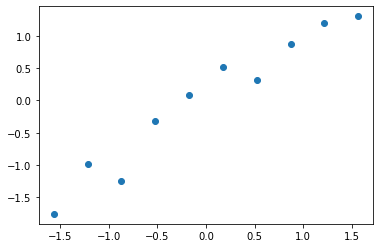

In [58]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.scatter(X, y)


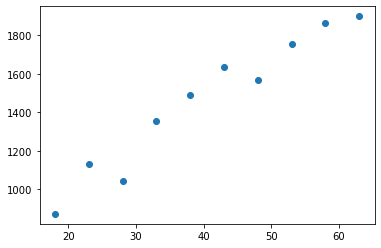

In [59]:
plt.scatter(XX, yy)

# Fórmula da regressão linear simples
y = b0 + b1 * x

In [60]:
np.random.seed(0)
np.random.rand(2)

array([0.5488135 , 0.71518937])

In [61]:
import tensorflow.compat.v1 as tf
tf.disable_v2_behavior()

In [62]:
b0 = tf.Variable(0.54)
b1 = tf.Variable(0.71)

In [63]:
erro = tf.losses.mean_squared_error(y, (b0 + b1 * X))
otimizador = tf.train.GradientDescentOptimizer(learning_rate = 0.001)
treinamento = otimizador.minimize(erro)
init = tf.global_variables_initializer()

In [72]:
with tf.Session() as sess:
    sess.run(init)
    for i in range(1000):
        print(sess.run(b0))
        print(sess.run(b1))
        print(" ")
        sess.run(treinamento)
    b0_final, b1_final = sess.run([b0, b1])

0.54
0.71
 
0.53892004
0.71052235
 
0.5378422
0.7110437
 
0.5367665
0.711564
 
0.535693
0.7120833
 
0.5346216
0.7126015
 
0.53355235
0.7131187
 
0.53248525
0.7136348
 
0.5314203
0.7141499
 
0.5303574
0.714664
 
0.5292967
0.71517706
 
0.5282381
0.71568906
 
0.5271816
0.71620005
 
0.5261273
0.71671003
 
0.525075
0.717219
 
0.52402484
0.71772695
 
0.5229768
0.7182339
 
0.5219309
0.7187398
 
0.520887
0.7192447
 
0.51984525
0.7197486
 
0.51880556
0.7202515
 
0.51776797
0.7207534
 
0.51673245
0.7212542
 
0.51569897
0.7217541
 
0.5146676
0.72225296
 
0.51363826
0.72275084
 
0.512611
0.7232477
 
0.5115858
0.7237436
 
0.5105626
0.7242385
 
0.50954145
0.7247324
 
0.5085224
0.7252253
 
0.50750536
0.72571725
 
0.50649035
0.7262082
 
0.50547737
0.72669816
 
0.5044664
0.72718716
 
0.5034575
0.72767514
 
0.5024506
0.72816217
 
0.5014457
0.72864825
 
0.5004428
0.7291333
 
0.49944192
0.7296174
 
0.49844304
0.7301006
 
0.49744615
0.7305828
 
0.49645126
0.73106396
 
0.49545836
0.7315442
 
0.49446744
0.73

In [65]:
b0_final

0.07293496

In [66]:
b1_final

0.9359134

In [67]:
previsoes = b0_final + b1_final * X
previsoes

array([[-1.39335951],
       [-1.06751629],
       [-0.74167308],
       [-0.41582986],
       [-0.08998665],
       [ 0.23585657],
       [ 0.56169979],
       [ 0.887543  ],
       [ 1.21338622],
       [ 1.53922944]])

In [68]:
type(previsoes)

numpy.ndarray

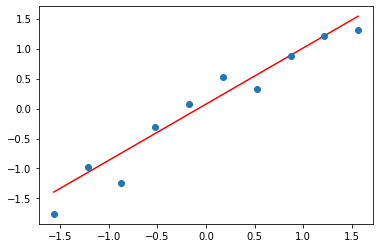

In [69]:
plt.plot(X, previsoes, color = 'red')
plt.plot(X, y, 'o')

In [70]:
scaler_x.transform(40)

ValueError: Expected 2D array, got scalar array instead:
array=40.0.
Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample.

In [ ]:
previsao = scaler_y.inverse_transform(b0_final + b1_final * scaler_x.transform(40))
previsao

array([[1475.15950152]])

In [ ]:
y1 = scaler_y.inverse_transform(y)
y1

array([[ 871.],
       [1132.],
       [1042.],
       [1356.],
       [1488.],
       [1638.],
       [1569.],
       [1754.],
       [1866.],
       [1900.]])

In [ ]:
previsoes1 = scaler_y.inverse_transform(previsoes)
previsoes1

array([[ 993.37307127],
       [1102.86998723],
       [1212.3669032 ],
       [1321.86381917],
       [1431.36073513],
       [1540.8576511 ],
       [1650.35456707],
       [1759.85148303],
       [1869.348399  ],
       [1978.84531497]])

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
mae = mean_absolute_error(y1, previsoes1)
mse = mean_squared_error(y1, previsoes1)

In [ ]:
mae

67.91875458994167

In [ ]:
mse

7153.9129941765395